# Optimization: Post-Training INT8 Quantization

**Goal.** Make Model 4 cheaper to deploy: a smaller file and faster CPU inference, without a meaningful loss in segmentation quality. Flood mapping is typically run on large batches of tiles, often on CPU-only servers, so file size and CPU latency matter more than GPU speed.

**Approach.**
1. Export the best Model 4 checkpoint to ONNX (FP32).
2. Apply *static* post-training quantization with ONNX Runtime: weights and activations are converted to INT8 (QDQ format, per-channel weight scales). Activation ranges are estimated by running 128 calibration tiles through the model — half flood-rich tiles, half random tiles from the training set.
3. Compare PyTorch FP32 (CPU), ONNX FP32 and ONNX INT8 on the **same** validation subset: file size, single-tile CPU latency, IoU / precision / recall / F1 and pixel-wise agreement with the FP32 output.

**Why static and not dynamic quantization.** PyTorch's dynamic quantization only converts `Linear` / recurrent layers. A U-Net is almost entirely convolutions, so it would change almost nothing. Convolutions need static quantization with calibration data.

**Design decisions and risks.**
- The final segmentation-head convolution is kept in FP32: it produces the logits and is the layer most sensitive to rounding, and it is tiny.
- SAR tiles contain speckle noise and extreme values, which can stretch the activation ranges seen during calibration and waste INT8 resolution. I used Min/max calibration as the baseline; percentile or entropy calibration is the next thing to try if F1 drops noticeably.
- The threshold tuned for FP32 is reused for INT8, although the probability distribution may shift slightly after quantization.

**Hypothesis.** About 4x smaller file, a clear CPU speed-up (the factor depends on the CPU's INT8 support, e.g. AVX512-VNNI), and an F1 drop of roughly one point or less.

In [83]:
!pip install -q onnx onnxruntime

In [ ]:
import os
import time
import shutil
import numpy as np
import torch
import onnx
import onnxruntime as ort
from onnxruntime.quantization import quantize_static, CalibrationDataReader, QuantType, QuantFormat
from onnxruntime.quantization.shape_inference import quant_pre_process

ARTIFACT_DIR = 'app/artifacts'
os.makedirs(ARTIFACT_DIR, exist_ok=True)
os.makedirs('app/samples', exist_ok=True)

# Best-validation-loss checkpoint of Model 1, saved during training in Kaggle's working folder
CKPT = '/kaggle/working/model_1_BCE.pth'
assert os.path.exists(CKPT), f'Checkpoint not found: {CKPT}'

# Model 1 = U-Net / ResNet34 with ONE output channel (BCE loss -> sigmoid gives the flood probability).
net = create_model(num_classes=1, encoder_weights=None)  
net.load_state_dict(torch.load(CKPT, map_location='cpu'))
net.eval().cpu()
print(f'Loaded checkpoint: {CKPT}')

# export to ONNX (dynamic batch and spatial size) 
FP32_PATH = f'{ARTIFACT_DIR}/model_fp32.onnx'
dummy = torch.rand(1, 3, 256, 256)
export_kwargs = dict(
    input_names=['input'], output_names=['logits'],
    dynamic_axes={'input': {0: 'batch', 2: 'height', 3: 'width'},
                  'logits': {0: 'batch', 2: 'height', 3: 'width'}},
    opset_version=17,
)
try:
    torch.onnx.export(net, dummy, FP32_PATH, dynamo=False, **export_kwargs)   # classic exporter
except TypeError:                                                             # older PyTorch
    torch.onnx.export(net, dummy, FP32_PATH, **export_kwargs)
onnx.checker.check_model(onnx.load(FP32_PATH))

# sanity check: ONNX output must match PyTorch 
with torch.no_grad():
    ref = net(dummy).numpy()
out = ort.InferenceSession(FP32_PATH, providers=['CPUExecutionProvider']).run(None, {'input': dummy.numpy()})[0]
print(f'FP32 ONNX exported: {os.path.getsize(FP32_PATH) / 1e6:.1f} MB')
print('max |PyTorch - ONNX| on logits:', float(np.abs(ref - out).max()))

Loaded checkpoint: /kaggle/working/model_1_BCE.pth


/tmp/ipykernel_123/2028417429.py:36: DeprecationWarning: You are using the legacy TorchScript-based ONNX export. Starting in PyTorch 2.9, the new torch.export-based ONNX exporter has become the default. Learn more about the new export logic: https://docs.pytorch.org/docs/stable/onnx_export.html. For exporting control flow: https://pytorch.org/tutorials/beginner/onnx/export_control_flow_model_to_onnx_tutorial.html
  torch.onnx.export(net, dummy, FP32_PATH, dynamo=False, **export_kwargs)   # classic exporter


FP32 ONNX exported: 97.7 MB
max |PyTorch - ONNX| on logits: 5.7220458984375e-06


In [87]:
# calibration data: same pre-processing as training, no augmentation 
class TileCalibrationReader(CalibrationDataReader):
    def __init__(self, tiles, input_name='input'):
        self._iter = iter([{input_name: t[None].astype(np.float32)} for t in tiles])

    def get_next(self):
        return next(self._iter, None)


N_CALIB = 128
calib_df = pd.concat([
    train_df_undersample.sample(N_CALIB // 2, random_state=42),   # flood-rich tiles
    train_df.sample(N_CALIB // 2, random_state=42),               # random tiles
]).reset_index(drop=True)
calib_ds = ETCIDataset(calib_df, transform=None)
calib_tiles = [calib_ds[i][0].numpy() for i in range(len(calib_ds))]
print('Calibration tiles:', len(calib_tiles), calib_tiles[0].shape)

# static INT8 quantization
PRE_PATH = f'{ARTIFACT_DIR}/model_fp32_prep.onnx'
INT8_PATH = f'{ARTIFACT_DIR}/model_int8.onnx'
try:
    quant_pre_process(FP32_PATH, PRE_PATH, skip_symbolic_shape=False)
except Exception as e:
    print('Symbolic shape inference failed, using ONNX shape inference only:', e)
    quant_pre_process(FP32_PATH, PRE_PATH, skip_symbolic_shape=True)

# keep the final segmentation-head convolution in FP32
head_nodes = [n.name for n in onnx.load(PRE_PATH).graph.node
              if n.op_type == 'Conv' and 'segmentation_head' in n.name]
print('Kept in FP32:', head_nodes)

quantize_static(
    PRE_PATH, INT8_PATH, TileCalibrationReader(calib_tiles),
    quant_format=QuantFormat.QDQ,
    activation_type=QuantType.QUInt8,      # U8S8 is the recommended combination for x86 CPUs
    weight_type=QuantType.QInt8,
    per_channel=True,
    nodes_to_exclude=head_nodes,
)
os.remove(PRE_PATH)
print(f'INT8 ONNX written: {os.path.getsize(INT8_PATH) / 1e6:.1f} MB')

Calibration tiles: 128 (3, 256, 256)
Kept in FP32: ['/segmentation_head/segmentation_head.0/Conv']
INT8 ONNX written: 24.7 MB


### Benchmark: size, CPU latency and quality

All three variants are evaluated on the same random subset of the validation tiles. Latency is the median over repeated single-tile (batch size 1) CPU runs after a warm-up. Metrics are pooled over all pixels (the same confusion-matrix approach as `EvalTracker`) and are reported at the default 0.5 threshold and at the F1-optimal threshold found for Model 4. The agreement column is the share of pixels where the mask equals the ONNX FP32 mask.

In [89]:
# evaluation subset (identical for every variant)
N_EVAL = 300
eval_ds = ETCIDataset(valid_df.sample(N_EVAL, random_state=0).reset_index(drop=True), transform=None)
X_eval = np.stack([eval_ds[i][0].numpy() for i in range(len(eval_ds))])                         # (N, 3, H, W)
Y_eval = np.stack([eval_ds[i][1].numpy()[0] for i in range(len(eval_ds))]).astype(np.uint8)    # (N, H, W)
THR_TUNED = 0.441    # F1-optimal threshold of Model 1 on the validation set (from the final table)
print('Eval tiles:', X_eval.shape, '| tuned threshold:', THR_TUNED)

n_threads = os.cpu_count()
torch.set_num_threads(n_threads)
so = ort.SessionOptions()
so.intra_op_num_threads = n_threads
sess_fp32 = ort.InferenceSession(FP32_PATH, so, providers=['CPUExecutionProvider'])
sess_int8 = ort.InferenceSession(INT8_PATH, so, providers=['CPUExecutionProvider'])


def sigmoid_flood(logits):
    """Model 1 has ONE output channel: sigmoid turns the logit into the flood probability."""
    return 1.0 / (1.0 + np.exp(-np.clip(logits[:, 0], -30, 30)))


def onnx_probs(sess, X, bs=8):
    return np.concatenate([sigmoid_flood(sess.run(None, {'input': X[i:i + bs]})[0])
                           for i in range(0, len(X), bs)])


def torch_probs(model, X, bs=8):
    outs = []
    with torch.no_grad():
        for i in range(0, len(X), bs):
            outs.append(torch.sigmoid(model(torch.from_numpy(X[i:i + bs])))[:, 0].numpy())
    return np.concatenate(outs)


def seg_metrics(prob, Y, thr):
    pred = prob >= thr
    tp = np.sum(pred & (Y == 1)); fp = np.sum(pred & (Y == 0)); fn = np.sum(~pred & (Y == 1))
    iou = tp / (tp + fp + fn + 1e-9)
    prec = tp / (tp + fp + 1e-9)
    rec = tp / (tp + fn + 1e-9)
    return {'IoU': iou, 'Precision': prec, 'Recall': rec, 'F1': 2 * prec * rec / (prec + rec + 1e-9)}


def median_latency(fn, x, n=30, warmup=5):
    for _ in range(warmup):
        fn(x)
    times = []
    for _ in range(n):
        t0 = time.perf_counter(); fn(x); times.append((time.perf_counter() - t0) * 1000)
    return float(np.median(times)), float(np.percentile(times, 90))


def torch_forward(x):
    with torch.no_grad():
        return net(torch.from_numpy(x))


x1 = X_eval[:1]
candidates = {
    'PyTorch FP32 (CPU)': (lambda X: torch_probs(net, X), torch_forward, CKPT),
    'ONNX FP32':          (lambda X: onnx_probs(sess_fp32, X), lambda x: sess_fp32.run(None, {'input': x}), FP32_PATH),
    'ONNX INT8':          (lambda X: onnx_probs(sess_int8, X), lambda x: sess_int8.run(None, {'input': x}), INT8_PATH),
}

all_probs, rows = {}, []
for name, (prob_fn, fwd, size_file) in candidates.items():
    print('Evaluating', name, '...')
    p = prob_fn(X_eval)
    all_probs[name] = p
    med, p90 = median_latency(fwd, x1)
    m05, mt = seg_metrics(p, Y_eval, 0.5), seg_metrics(p, Y_eval, THR_TUNED)
    rows.append({
        'Model': name,
        'Size (MB)': os.path.getsize(size_file) / 1e6,
        'Latency median (ms/tile)': med,
        'Latency p90 (ms/tile)': p90,
        'IoU @0.5': m05['IoU'], 'Precision @0.5': m05['Precision'],
        'Recall @0.5': m05['Recall'], 'F1 @0.5': m05['F1'],
        f'F1 @{THR_TUNED:.2f}': mt['F1'],
    })

ref_mask = all_probs['ONNX FP32'] >= THR_TUNED
for r in rows:
    r['Agreement with ONNX FP32 (%)'] = 100 * float(((all_probs[r['Model']] >= THR_TUNED) == ref_mask).mean())

results_df = pd.DataFrame(rows).set_index('Model')
results_df.to_csv('quantization_results.csv')
display(results_df.round(4))

fp, i8 = results_df.loc['ONNX FP32'], results_df.loc['ONNX INT8']
print(f"\nSize reduction (ONNX FP32 -> INT8): {fp['Size (MB)'] / i8['Size (MB)']:.2f}x")
print(f"CPU speed-up   (ONNX FP32 -> INT8): {fp['Latency median (ms/tile)'] / i8['Latency median (ms/tile)']:.2f}x")
print(f"F1 @0.5 change (INT8 - FP32)       : {i8['F1 @0.5'] - fp['F1 @0.5']:+.4f}")

Eval tiles: (300, 3, 256, 256) | tuned threshold: 0.441
Evaluating PyTorch FP32 (CPU) ...
Evaluating ONNX FP32 ...
Evaluating ONNX INT8 ...


,Size (MB),Latency median (ms/tile),Latency p90 (ms/tile),IoU @0.5,Precision @0.5,Recall @0.5,F1 @0.5,F1 @0.44,Agreement with ONNX FP32 (%)
Model,,,,,,,,,
PyTorch FP32 (CPU),97.9205,101.4751,104.9176,0.7722,0.9317,0.8185,0.8714,0.8707,100.0000
ONNX FP32,97.7443,73.6623,76.1032,0.7722,0.9317,0.8185,0.8714,0.8707,100.0000
ONNX INT8,24.7139,61.5373,63.6520,0.6789,0.7969,0.8210,0.8088,0.8039,99.4869



Size reduction (ONNX FP32 -> INT8): 3.96x
CPU speed-up   (ONNX FP32 -> INT8): 1.20x
F1 @0.5 change (INT8 - FP32)       : -0.0627


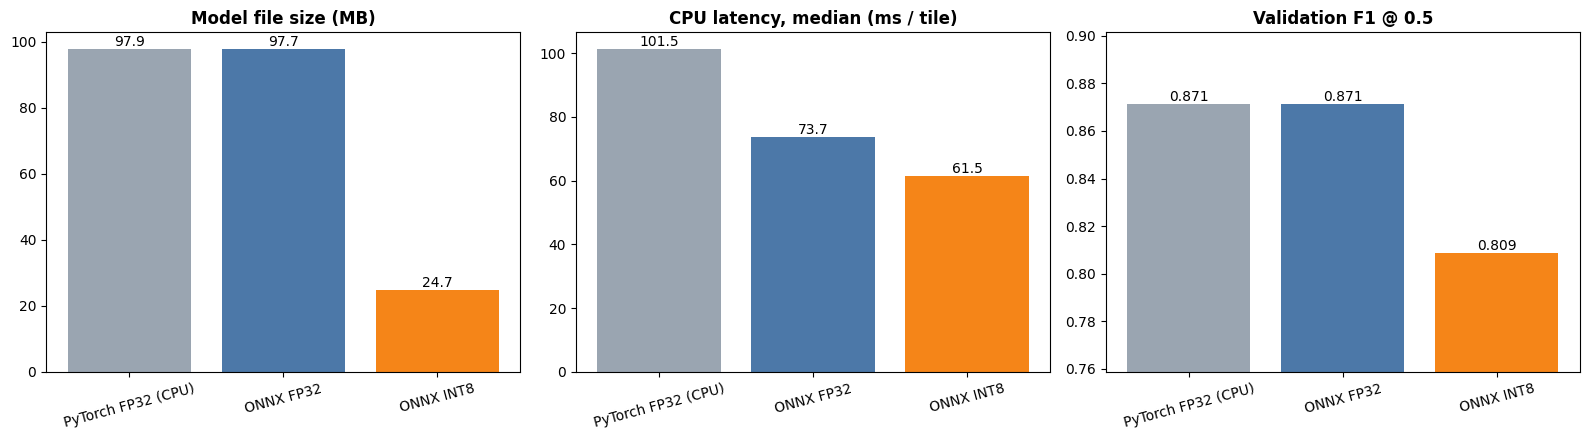

In [91]:
# bar charts 
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
names = list(results_df.index)
colors = ['#9aa5b1', '#4c78a8', '#f58518']
for ax, col, title in zip(axes,
                          ['Size (MB)', 'Latency median (ms/tile)', 'F1 @0.5'],
                          ['Model file size (MB)', 'CPU latency, median (ms / tile)', 'Validation F1 @ 0.5']):
    vals = results_df[col].values
    ax.bar(names, vals, color=colors)
    ax.set_title(title, fontweight='bold')
    ax.tick_params(axis='x', rotation=15)
    for j, v in enumerate(vals):
        ax.text(j, v, f'{v:.3f}' if col == 'F1 @0.5' else f'{v:.1f}', ha='center', va='bottom')
    if col == 'F1 @0.5':
        ax.set_ylim(max(0, vals.min() - 0.05), min(1, vals.max() + 0.03))
plt.tight_layout()
plt.show()

**Quantization results**
- **Size:** the INT8 model is about 4x smaller (24.7 MB vs 97.7 MB).
- **Speed:** ONNX FP32 is faster than PyTorch on the CPU (73.7 vs 101.5 ms per tile), and INT8 is a bit faster again (61.5 ms, about 1.2x faster than ONNX FP32).
- **Quality:** converting to ONNX FP32 changes nothing (F1 0.871 for both). INT8 loses quality: F1 drops from 0.871 to 0.809, about 6 points. The loss of more than 0.01 is larger than the limit I set for accepting the INT8 model.
- **Conclusion:** INT8 gives a much smaller model and a moderate speed-up, but the quality loss is too big to use as it is. Next I would try percentile or entropy calibration, which is less affected by the extreme SAR values. Until then, the ONNX FP32 model is the safer choice for deployment.
- These F1 values come from a random subset of 300 validation tiles, so they are higher than the full-validation F1 of 0.839.

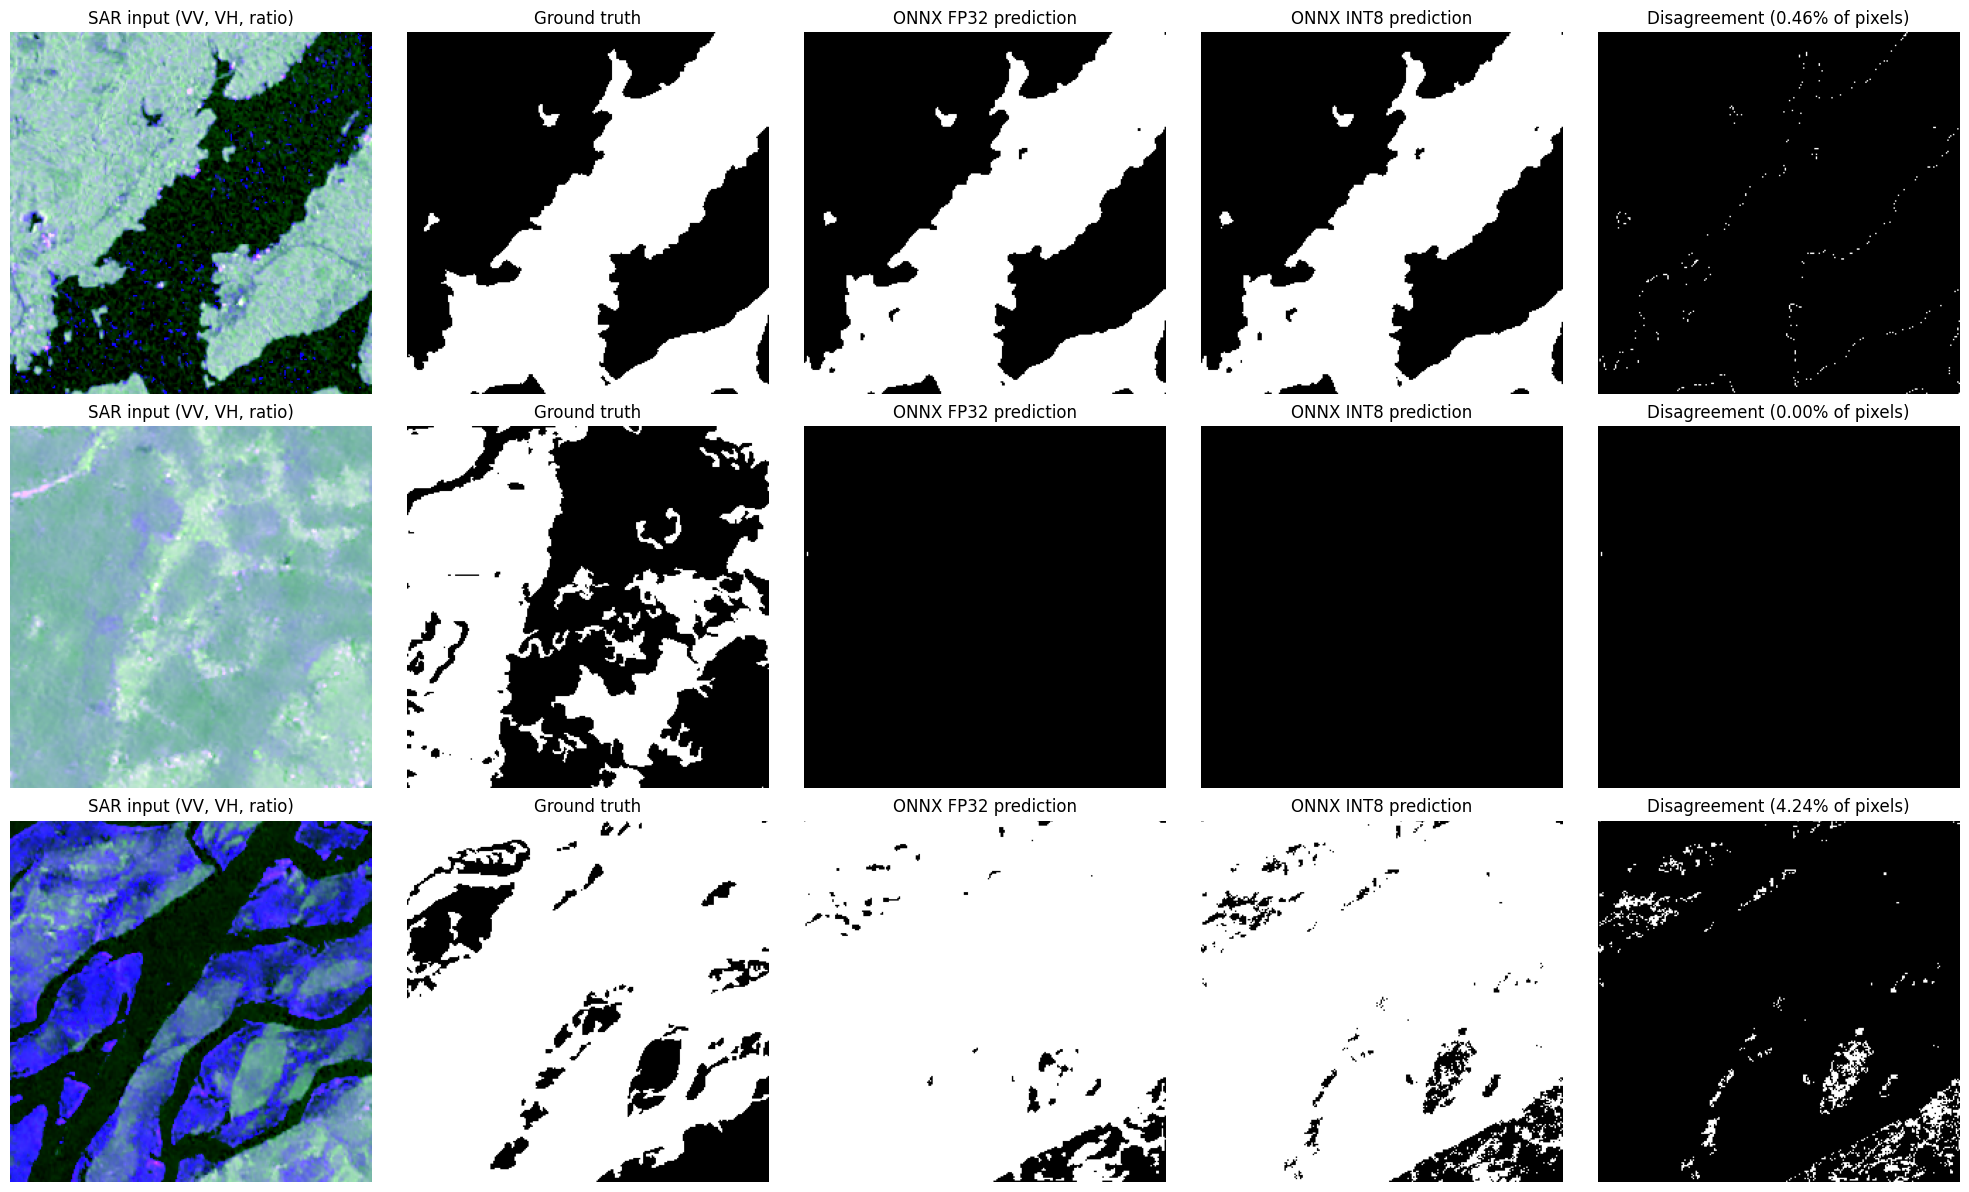

{
  "threshold": 0.441,
  "model": "U-Net / ResNet34, 2 output classes",
  "input": "VV, VH, clip(VV/VH, 0, 1), all in [0, 1]"
}


In [93]:
# qualitative check: where do FP32 and INT8 disagree?
idx = np.argsort(Y_eval.sum(axis=(1, 2)))[-3:]
fig, axes = plt.subplots(len(idx), 5, figsize=(20, 4 * len(idx)))
for r, k in enumerate(idx):
    m32 = all_probs['ONNX FP32'][k] >= THR_TUNED
    m8 = all_probs['ONNX INT8'][k] >= THR_TUNED
    panels = [(X_eval[k].transpose(1, 2, 0), 'SAR input (VV, VH, ratio)'),
              (Y_eval[k], 'Ground truth'),
              (m32, 'ONNX FP32 prediction'),
              (m8, 'ONNX INT8 prediction'),
              (m32 ^ m8, f'Disagreement ({100 * (m32 ^ m8).mean():.2f}% of pixels)')]
    for c, (img, title) in enumerate(panels):
        axes[r, c].imshow(img, cmap=None if c == 0 else 'gray')
        axes[r, c].set_title(title)
        axes[r, c].axis('off')
plt.tight_layout()
plt.show()

# default threshold used by the demo app 
with open(f'{ARTIFACT_DIR}/config.json', 'w') as f:
    json.dump({'threshold': THR_TUNED, 'model': 'U-Net / ResNet34, 2 output classes',
               'input': 'VV, VH, clip(VV/VH, 0, 1), all in [0, 1]'}, f, indent=2)
print(open(f'{ARTIFACT_DIR}/config.json').read())

**Qualitative check: FP32 vs INT8 (the 3 tiles with the most flood in the evaluation subset)**
- **Tile 1 (clear, large flood):** both models follow the ground truth closely. FP32 and INT8 differ on only 0.46% of the pixels, along the edges of the flooded area. Quantization has almost no effect on easy tiles.
- **Tile 2 (missed flood):** the ground truth has a lot of flood, but both models predict none. The SAR image has no clearly dark water here, which is a model limitation. FP32 and INT8 agree (0.00% difference), so quantization is not the cause.
- **Tile 3 (patchy, hard scene):** this is where the models differ most (4.24% of the pixels). The INT8 mask is noisier, with more scattered patches. This is where most of the F1 loss from quantization comes from.
- **Overall:** quantization mostly changes borderline pixels in complex scenes, which fits the drop in F1 from 0.871 to 0.809. These three tiles are the most flooded ones, not random, so they show the hardest cases and not the average.

let's save the quantized model

In [96]:
OUT_PATH = '/kaggle/working/model_1_fp32.onnx'         
shutil.copy(FP32_PATH, OUT_PATH)

print(f'Saved: {OUT_PATH} ({os.path.getsize(OUT_PATH) / 1e6:.1f} MB)')

Saved: /kaggle/working/model_1_fp32.onnx (97.7 MB)
